# Phase 2 — Exploratory Data Analysis (EDA) & Statistical Astronomy

**Project:** Astronomical Object Classification Using Machine Learning  
**Dataset:** `sdss_cleaned.csv` from Phase 1 | **Target:** `class` ∈ {STAR, GALAXY, QSO}  
**Main inputs for later ML:** `u`, `g`, `r`, `i`, `z`  

### Learning objectives

1. Describe **central tendency** (mean, median, approximate mode) and **dispersion** (variance, standard deviation, IQR).
2. Measure **shape** (skewness, kurtosis) and visually inspect distributions and unusual observations.
3. Study the differences between STAR, GALAXY and QSO observations.
4. Compare **Pearson** and **Spearman** correlations between photometric bands.
5. Create and interpret astronomical **colour indices**: $u-g$, $g-r$, $r-i$, $i-z$.
6. Perform an exploratory statistical comparison using **Kruskal–Wallis** and **$\eta^2$ effect sizes**.
7. Produce reproducible figures, dashboard extracts and a report for your chalk talk.

> **Scientific scope:** This is descriptive and inferential EDA, not model training. `redshift` is **spectroscopic** and is *not* part of the baseline photometry-only classifier. No outliers are removed in Phase 2 merely because they are extreme.

**Source notes:** [SDSS five-band imaging](https://www.sdss4.org/dr12/imaging/understanding-the-imaging-data/) · [SDSS magnitudes](https://www.sdss4.org/dr17/algorithms/magnitudes/) · [Kaggle dataset](https://www.kaggle.com/datasets/fedesoriano/stellar-classification-dataset-sdss17).

## 0. Imports, paths and reproducibility

Run the notebook from either the project root or `notebooks/`. All figures are saved under `figures/eda/`, and all tabular summaries under `reports/` or `dashboard/`. Random sampling uses fixed seeds.

In [1]:
from pathlib import Path
import json
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from scipy import stats

SEED = 42
BANDS = ["u", "g", "r", "i", "z"]
COLORS = ["u_g", "g_r", "r_i", "i_z"]
CLASSES = ["STAR", "GALAXY", "QSO"]
CLASS_COLOR = {"STAR": "#c58c27", "GALAXY": "#7663b4", "QSO": "#168c98"}

# Search upward so execution works from root or from /notebooks.
ROOT = None
for path in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
    if (path / "data" / "processed" / "sdss_cleaned.csv").exists():
        ROOT = path
        break
if ROOT is None:
    raise FileNotFoundError("Missing data/processed/sdss_cleaned.csv. Extract the Phase 2 ZIP first.")

DATA_FILE = ROOT / "data" / "processed" / "sdss_cleaned.csv"
FIG_DIR = ROOT / "figures" / "eda"
REPORT_DIR = ROOT / "reports"
DASH_DIR = ROOT / "dashboard"
for folder in (FIG_DIR, REPORT_DIR, DASH_DIR):
    folder.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.figsize": (10, 5), "figure.dpi": 105,
    "savefig.dpi": 160, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.labelcolor": "#273244",
    "axes.grid": False,
})

def save_plot(name):
    plt.savefig(FIG_DIR / name, dpi=160, bbox_inches="tight", facecolor="white")
    plt.show()

print("Project root:", ROOT)
print("Input:", DATA_FILE)

Project root: C:\Users\daksh\OneDrive\Desktop\ML Project\Astronomical-Object-Classification
Input: C:\Users\daksh\OneDrive\Desktop\ML Project\Astronomical-Object-Classification\data\processed\sdss_cleaned.csv


## 1. Load and validate the Phase 1 cleaned dataset

The raw dataset had **100,000** rows. Phase 1 removed one row with invalid `-9999` values in the photometric bands. We must verify that Phase 2 is using the cleaned version, not the raw file.

**Important:** Some original survey IDs were rounded in the published CSV. We load them as strings and never use them as quantitative variables.

In [2]:
df = pd.read_csv(DATA_FILE, dtype={"obj_ID": "string", "spec_obj_ID": "string"})
required = set(BANDS + ["alpha", "delta", "redshift", "class"])
assert required.issubset(df.columns), "Expected SDSS columns are missing."
assert df.shape == (99999, 18), f"Unexpected shape: {df.shape}"
assert df[BANDS].notna().all().all(), "There are missing photometric values."
assert not df[BANDS].eq(-9999).any().any(), "Invalid -9999 sentinel remains."
assert set(df["class"].unique()) == set(CLASSES), "Unexpected class labels."

print("Dataset shape:", df.shape)
print("Missing cells:", int(df.isna().sum().sum()))
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Unique labels:", df["class"].unique().tolist())
display(df.head())

Dataset shape: (99999, 18)
Missing cells: 0
Exact duplicate rows: 0
Unique labels: ['GALAXY', 'QSO', 'STAR']


,obj_ID,alpha,delta,u,g,r,i,z,run_ID,rerun_ID,cam_col,field_ID,spec_obj_ID,class,redshift,plate,MJD,fiber_ID
0,1.23766E+18,135.689107,32.494632,23.87882,22.27530,20.39501,19.16573,18.79371,3606,301,2,79,6.54378E+18,GALAXY,0.634794,5812,56354,171
1,1.23766E+18,144.826101,31.274185,24.77759,22.83188,22.58444,21.16812,21.61427,4518,301,5,119,1.17601E+19,GALAXY,0.779136,10445,58158,427
2,1.23766E+18,142.188790,35.582444,25.26307,22.66389,20.60976,19.34857,18.94827,3606,301,2,120,5.1522E+18,GALAXY,0.644195,4576,55592,299
3,1.23766E+18,338.741038,-0.402828,22.13682,23.77656,21.61162,20.50454,19.25010,4192,301,3,214,1.03011E+19,GALAXY,0.932346,9149,58039,775
4,1.23768E+18,345.282593,21.183866,19.43718,17.58028,16.49747,15.97711,15.54461,8102,301,3,137,6.89186E+18,GALAXY,0.116123,6121,56187,842


## 2. Target variable and class imbalance

The dataset contains three known **spectroscopic classes**, but they are not equally frequent. A majority-class-only model can have deceptively high accuracy, so later we should report **macro F1-score** and **per-class recall**.

$	ext{Class percentage} = 100	imes n_{c}/N$.

,count,percent
class,,
STAR,21593,21.59
GALAXY,59445,59.45
QSO,18961,18.96


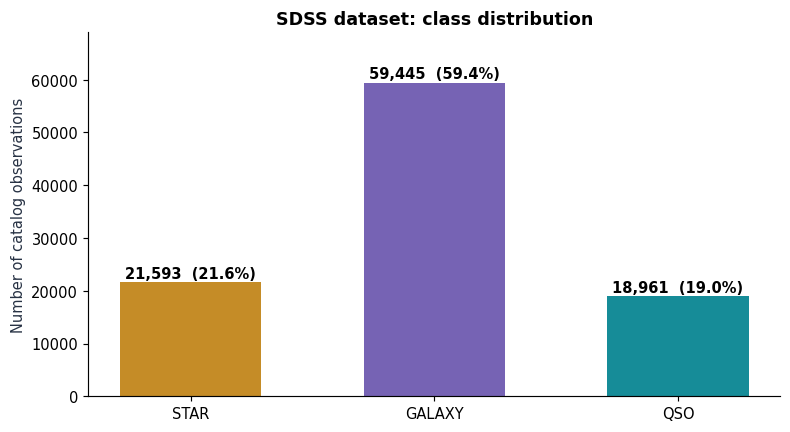

Majority-class accuracy baseline: 59.45%


In [3]:
counts = df["class"].value_counts().reindex(CLASSES)
class_table = pd.DataFrame({"count": counts, "percent": counts / len(df) * 100})
class_table.index.name = "class"
class_table.to_csv(REPORT_DIR / "phase2_class_distribution.csv")
display(class_table.round(2))

fig, ax = plt.subplots(figsize=(8.5, 4.5))
bars = ax.bar(CLASSES, counts.values, color=[CLASS_COLOR[k] for k in CLASSES], width=0.58)
for bar, amount in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 800,
            f"{amount:,}  ({amount / len(df):.1%})", ha="center", fontsize=10, fontweight="bold")
ax.set_ylabel("Number of catalog observations")
ax.set_title("SDSS dataset: class distribution")
ax.set_ylim(0, counts.max()*1.16)
save_plot("01_class_distribution.png")
print(f"Majority-class accuracy baseline: {counts.max()/len(df):.2%}")

## 3. Descriptive statistics for the five photometric bands

For each feature $x_1,\ldots,x_n$:

| Statistic | Formula / interpretation |
|---|---|
| Mean | $\bar{x}=\frac{1}{n}\sum_i x_i$; sensitive to extremes |
| Median | Middle value when observations are sorted; robust to extremes |
| Mode | Most common value; **raw exact mode is usually unhelpful for continuous measurements** |
| Sample variance | $s^2=\frac{1}{n-1}\sum_i(x_i-\bar{x})^2$ |
| Standard deviation | $s=\sqrt{s^2}$, in original magnitude units |
| IQR | $Q_3-Q_1$, robust measure of central spread |
| Skewness | Asymmetry: positive = longer right tail; negative = longer left tail |
| Excess kurtosis | Tail weight relative to normal distribution (normal = 0) |

For teaching purposes we compute an **approximate binned mode at 0.1 magnitude precision**. This is not the exact statistical mode of a continuous variable.

In [4]:
summary = pd.DataFrame(index=BANDS)
summary["mean"] = df[BANDS].mean()
summary["median"] = df[BANDS].median()
summary["mode_rounded_0.1"] = df[BANDS].round(1).mode().iloc[0]
summary["sample_variance"] = df[BANDS].var(ddof=1)
summary["sample_std"] = df[BANDS].std(ddof=1)
summary["min"] = df[BANDS].min()
summary["q1"] = df[BANDS].quantile(.25)
summary["q3"] = df[BANDS].quantile(.75)
summary["iqr"] = summary["q3"] - summary["q1"]
summary["max"] = df[BANDS].max()
summary["skewness"] = df[BANDS].skew()
summary["excess_kurtosis"] = df[BANDS].kurt()
summary.index.name = "band"
summary.to_csv(REPORT_DIR / "phase2_band_descriptive_statistics.csv")
display(summary.round(3))

,mean,median,mode_rounded_0.1,sample_variance,sample_std,min,q1,q3,iqr,max,skewness,excess_kurtosis
band,,,,,,,,,,,,
u,22.081,22.179,22.5,5.067,2.251,10.996,20.352,23.687,3.335,32.781,-0.070,-0.539
g,20.632,21.100,21.9,4.151,2.037,10.498,18.965,22.124,3.159,31.602,-0.428,-0.371
r,19.646,20.125,20.6,3.440,1.855,9.822,18.136,21.045,2.909,29.572,-0.508,-0.376
i,19.085,19.405,19.7,3.090,1.758,9.470,17.732,20.397,2.664,32.141,-0.404,-0.235
z,18.769,19.005,19.3,3.119,1.766,9.612,17.461,19.921,2.460,29.384,-0.257,-0.210


## 4. Histograms and class-wise magnitude distributions

A histogram shows the approximate distribution of each magnitude. **Lower astronomical magnitude means brighter observed flux**. Since we are plotting observed samples, large differences can reflect both physical properties and survey selection effects.

Each band is plotted by class on a common axis for that band, using 60 bins. This is density-normalized so each class is comparable despite class imbalance.

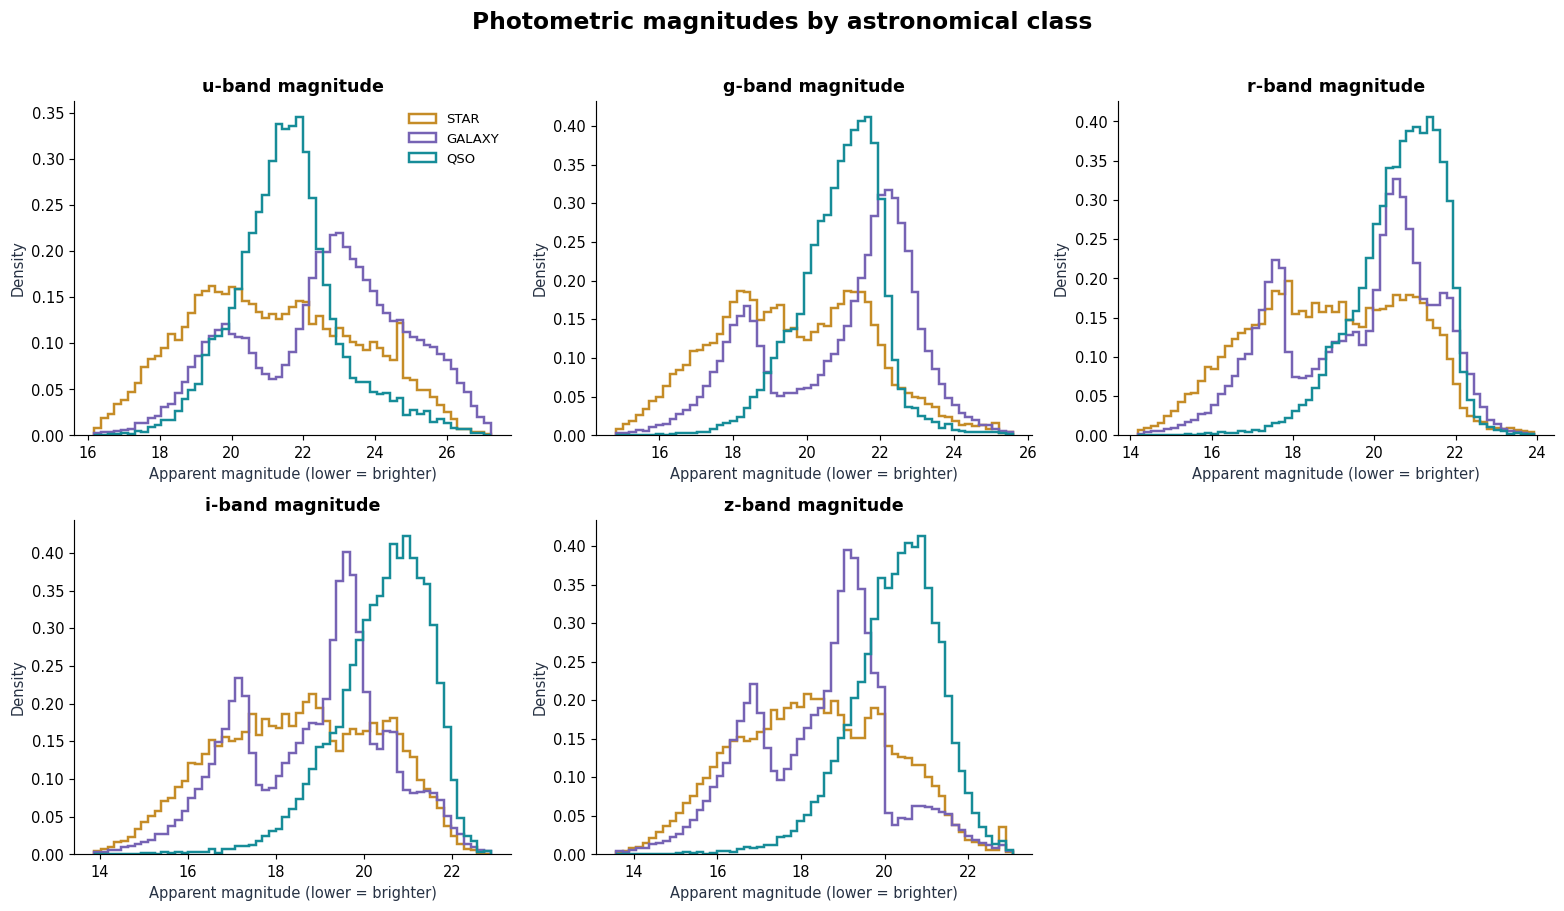

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8.5))
for ax, band in zip(axes.flat, BANDS):
    xlow, xhigh = df[band].quantile([.002, .998])
    bins = np.linspace(xlow, xhigh, 60)
    for cls in CLASSES:
        vals = df.loc[df["class"] == cls, band]
        ax.hist(vals, bins=bins, density=True, histtype="step", linewidth=1.7,
                label=cls, color=CLASS_COLOR[cls])
    ax.set_title(f"{band}-band magnitude")
    ax.set_xlabel("Apparent magnitude (lower = brighter)")
    ax.set_ylabel("Density")
axes.flat[-1].axis("off")
axes.flat[0].legend(frameon=False, fontsize=9)
fig.suptitle("Photometric magnitudes by astronomical class", fontsize=16, fontweight="bold", y=1.015)
fig.tight_layout()
save_plot("02_magnitude_histograms_by_class.png")

### Class medians and boxplots

Medians are more robust to unusual values than means. Side-by-side boxplots show overlap between classes and the central 50% range.

`showfliers=False` hides individual outlier markers **for readability only**; the rows are not removed.

,u,g,r,i,z
class,,,,,
STAR,21.011,19.543,18.955,18.592,18.319
GALAXY,22.842,21.582,20.105,19.224,18.767
QSO,21.503,21.056,20.773,20.582,20.374


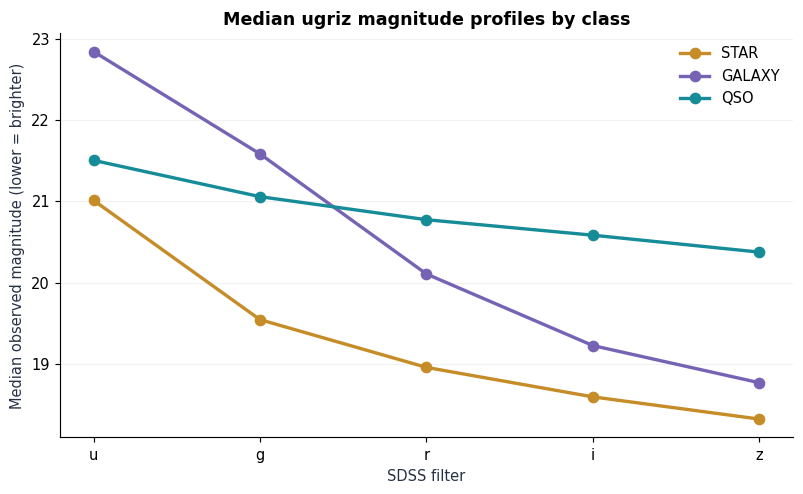

C:\Users\daksh\AppData\Local\Temp\ipykernel_15604\3736835396.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(arrays, labels=CLASSES, patch_artist=True, showfliers=False,
C:\Users\daksh\AppData\Local\Temp\ipykernel_15604\3736835396.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(arrays, labels=CLASSES, patch_artist=True, showfliers=False,
C:\Users\daksh\AppData\Local\Temp\ipykernel_15604\3736835396.py:19: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(arrays, labels=CLASSES, patch_artist=True, showfliers=False,
C:\Users\daksh\AppData\Local\Temp\ipykernel_15604\37

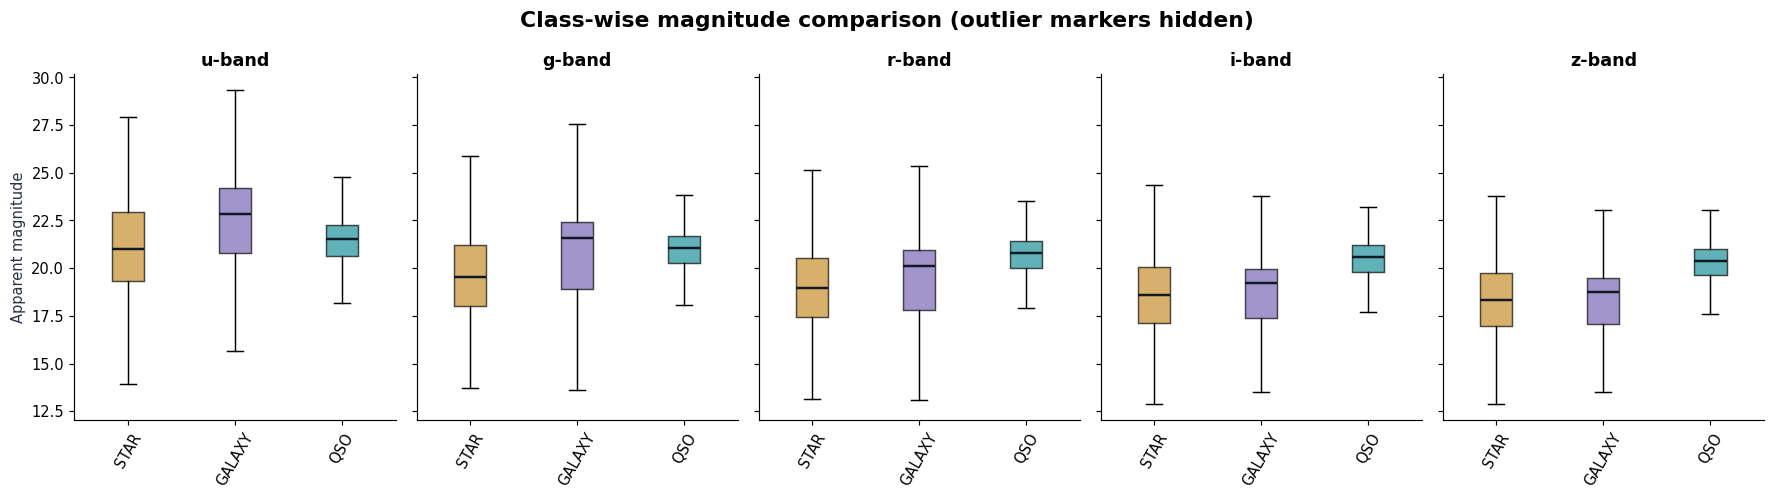

In [6]:
median_band = df.groupby("class")[BANDS].median().reindex(CLASSES)
median_band.to_csv(REPORT_DIR / "phase2_class_band_medians.csv")
display(median_band.round(3))

fig, ax = plt.subplots(figsize=(9, 5))
for cls in CLASSES:
    ax.plot(BANDS, median_band.loc[cls].to_numpy(), marker="o", linewidth=2.3,
            markersize=7, color=CLASS_COLOR[cls], label=cls)
ax.set_title("Median ugriz magnitude profiles by class")
ax.set_ylabel("Median observed magnitude (lower = brighter)")
ax.set_xlabel("SDSS filter")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=.16)
save_plot("03_median_magnitudes.png")

fig, axes = plt.subplots(1, 5, figsize=(17, 4.8), sharey=True)
for ax, band in zip(axes, BANDS):
    arrays = [df.loc[df["class"] == cls, band].to_numpy() for cls in CLASSES]
    bp = ax.boxplot(arrays, labels=CLASSES, patch_artist=True, showfliers=False,
                    medianprops={"color":"#121826", "linewidth":1.7})
    for patch, cls in zip(bp["boxes"], CLASSES):
        patch.set_facecolor(CLASS_COLOR[cls]); patch.set_alpha(.68)
    ax.set_title(band + "-band")
    ax.tick_params(axis="x", labelrotation=60)
axes[0].set_ylabel("Apparent magnitude")
fig.suptitle("Class-wise magnitude comparison (outlier markers hidden)", fontsize=15, fontweight="bold")
fig.tight_layout()
save_plot("04_magnitude_boxplots.png")

## 5. Pearson versus Spearman correlation

- **Pearson's $r$** measures *linear* association and is sensitive to extremes.
- **Spearman's $\rho$** measures *monotonic* rank association and is less sensitive to extreme scale values.
- A strong correlation does **not** establish causation or prove that one variable should be dropped.

Adjacent SDSS filters overlap in the information they capture, so correlation between neighbouring bands is expected.

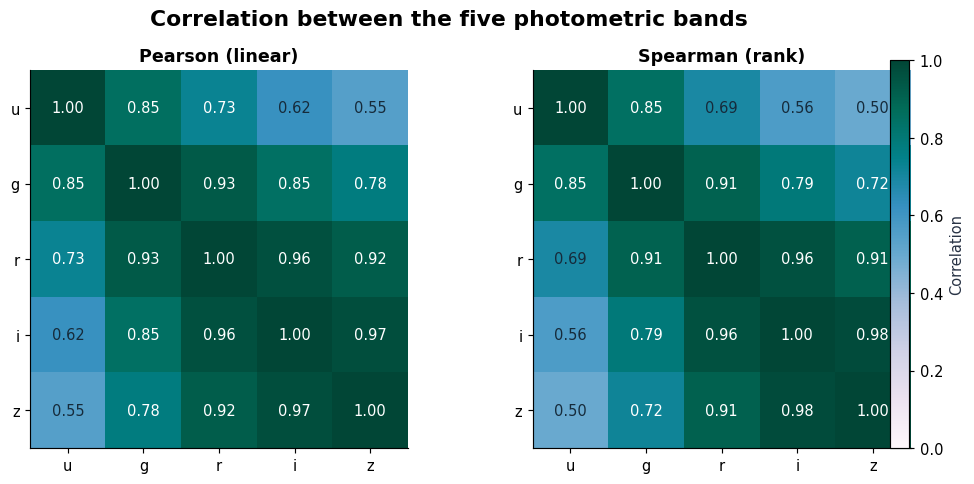

Pearson r(i,z): 0.9715
Pearson r(g,r): 0.933


In [7]:
pearson = df[BANDS].corr(method="pearson")
spearman = df[BANDS].corr(method="spearman")
pearson.to_csv(REPORT_DIR / "phase2_pearson_correlations.csv")
spearman.to_csv(REPORT_DIR / "phase2_spearman_correlations.csv")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))
for ax, matrix, title in [(axes[0], pearson, "Pearson (linear)"),
                          (axes[1], spearman, "Spearman (rank)")]:
    im = ax.imshow(matrix, cmap="PuBuGn", vmin=0, vmax=1)
    ax.set_xticks(range(len(BANDS)), BANDS)
    ax.set_yticks(range(len(BANDS)), BANDS)
    ax.set_title(title)
    for a in range(len(BANDS)):
        for b in range(len(BANDS)):
            val = matrix.iat[a, b]
            ax.text(b, a, f"{val:.2f}", ha="center", va="center",
                    color="white" if val > .7 else "#162b3b", fontsize=10)
fig.colorbar(im, ax=axes.ravel().tolist(), fraction=.023, pad=.03, label="Correlation")
fig.suptitle("Correlation between the five photometric bands", fontsize=15, fontweight="bold")
fig.subplots_adjust(top=.86, wspace=.28)
save_plot("05_correlations_pearson_spearman.png")
print("Pearson r(i,z):", round(float(pearson.loc["i","z"]), 4))
print("Pearson r(g,r):", round(float(pearson.loc["g","r"]), 4))

## 6. Feature engineering for EDA: colour indices

Astronomers often compare **differences of apparent magnitudes**. We can study four indices:

$$c_{ug}=u-g,\quad c_{gr}=g-r,\quad c_{ri}=r-i,\quad c_{iz}=i-z.$$

They describe the shape of the measured spectral energy distribution across adjacent filters, without directly measuring intrinsic luminosity.

> **Important:** These indices are *derived from existing magnitudes*, not independent measurements. Phase 4 will decide whether to use them as final ML inputs. In Phase 2 we calculate them only for analysis and dashboard exports.

,u_g,g_r,r_i,i_z
class,,,,
STAR,1.319,0.527,0.211,0.116
GALAXY,1.640,1.404,0.720,0.391
QSO,0.393,0.214,0.152,0.157


C:\Users\daksh\AppData\Local\Temp\ipykernel_15604\3878377581.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(samples, labels=CLASSES, patch_artist=True, showfliers=False,
C:\Users\daksh\AppData\Local\Temp\ipykernel_15604\3878377581.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(samples, labels=CLASSES, patch_artist=True, showfliers=False,
C:\Users\daksh\AppData\Local\Temp\ipykernel_15604\3878377581.py:15: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(samples, labels=CLASSES, patch_artist=True, showfliers=False,
C:\Users\daksh\AppData\Local\Temp\ipykernel_15604

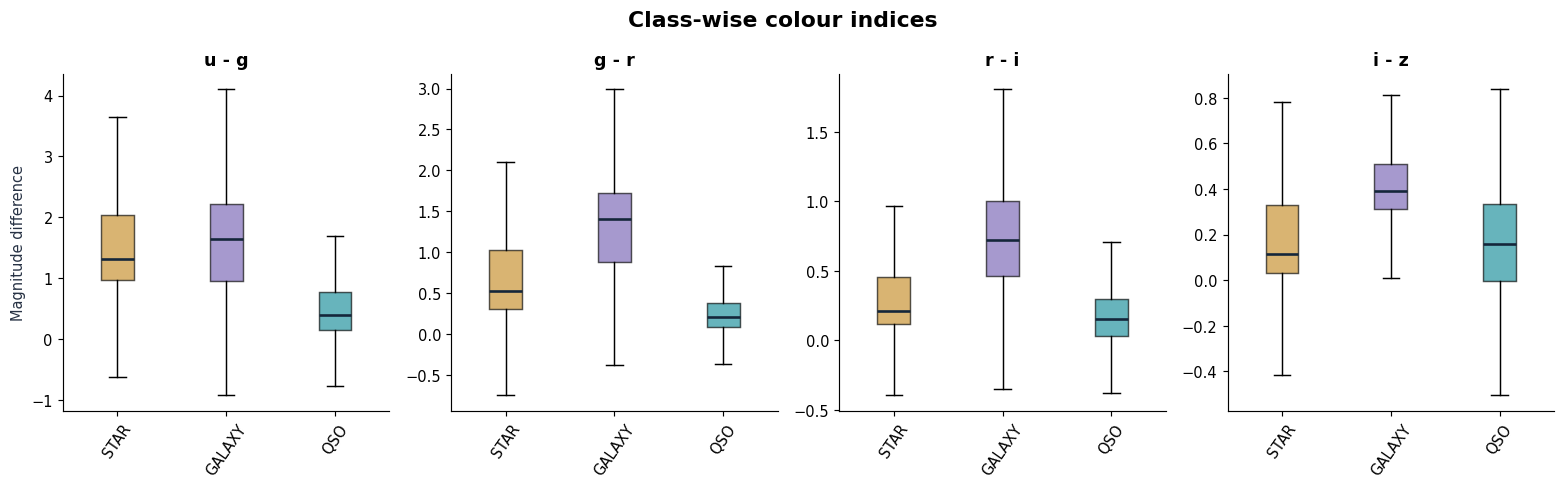

In [8]:
eda = df.copy()
eda["u_g"] = eda["u"] - eda["g"]
eda["g_r"] = eda["g"] - eda["r"]
eda["r_i"] = eda["r"] - eda["i"]
eda["i_z"] = eda["i"] - eda["z"]
assert len(eda) == len(df)

color_medians = eda.groupby("class")[COLORS].median().reindex(CLASSES)
color_medians.to_csv(REPORT_DIR / "phase2_class_color_medians.csv")
display(color_medians.round(3))

fig, axes = plt.subplots(1, 4, figsize=(15, 4.7))
for ax, feature in zip(axes, COLORS):
    samples = [eda.loc[eda["class"]==cls, feature] for cls in CLASSES]
    bp = ax.boxplot(samples, labels=CLASSES, patch_artist=True, showfliers=False,
                    medianprops={"color":"#14263a","linewidth":1.8})
    for patch, cls in zip(bp["boxes"], CLASSES):
        patch.set_facecolor(CLASS_COLOR[cls]); patch.set_alpha(.65)
    ax.set_title(feature.replace("_", " - "))
    ax.tick_params(axis="x", rotation=55)
axes[0].set_ylabel("Magnitude difference")
fig.suptitle("Class-wise colour indices", fontsize=15, fontweight="bold")
fig.tight_layout()
save_plot("06_color_index_boxplots.png")

### Colour–colour diagrams: visualizing class overlap

We plot `g-r` against `u-g` and `r-i` against `i-z` (two different pairs of indices). To prevent 100,000 overlapping points from hiding structure, we take a **fixed random sample of up to 3,000 observations per class**. This is a visualization sample only; it does not alter the full dataset.

There will be substantial overlap between the categories; these charts should not be interpreted as perfect decision boundaries.

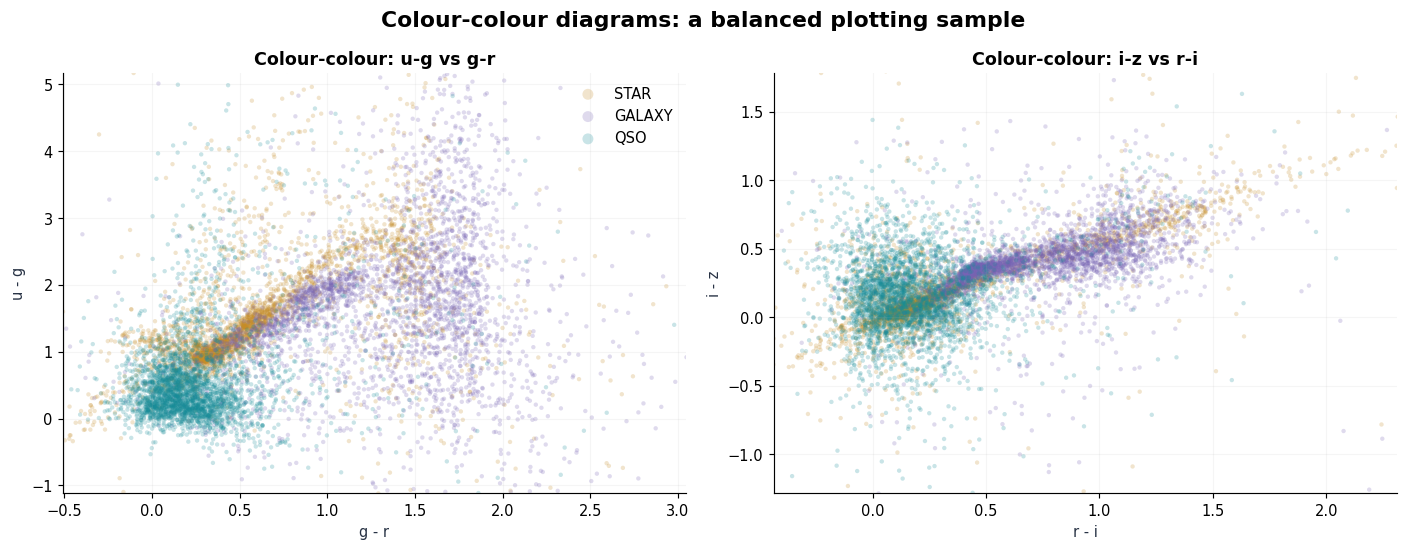

In [9]:
plot_samples = pd.concat([
    eda.loc[eda["class"]==cls].sample(n=min(3000, (eda["class"]==cls).sum()),random_state=SEED)
    for cls in CLASSES
], ignore_index=True)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.3))
for cls in CLASSES:
    subset = plot_samples.loc[plot_samples["class"]==cls]
    axes[0].scatter(subset["g_r"], subset["u_g"], s=9, alpha=.23,
                    color=CLASS_COLOR[cls], label=cls, edgecolors="none", rasterized=True)
    axes[1].scatter(subset["r_i"], subset["i_z"], s=9, alpha=.23,
                    color=CLASS_COLOR[cls], label=cls, edgecolors="none", rasterized=True)
axes[0].set(xlabel="g - r", ylabel="u - g", title="Colour-colour: u-g vs g-r")
axes[1].set(xlabel="r - i", ylabel="i - z", title="Colour-colour: i-z vs r-i")
# Percentile view for legibility: no data rows are removed.
for ax, xcol, ycol in [(axes[0],"g_r","u_g"), (axes[1],"r_i","i_z")]:
    ax.set_xlim(*np.quantile(plot_samples[xcol], [.005, .995]))
    ax.set_ylim(*np.quantile(plot_samples[ycol], [.005, .995]))
    ax.grid(alpha=.12)
axes[0].legend(markerscale=2.5, frameon=False, loc="best")
fig.suptitle("Colour-colour diagrams: a balanced plotting sample", fontsize=15, fontweight="bold")
fig.tight_layout()
save_plot("07_color_color_diagrams.png")

## 7. Exploratory astronomical interpretation of redshift

**Redshift is not part of the main photometry-only model.** Here we use it only to understand the dataset's spectroscopically labeled classes.

$z=(\lambda_{\mathrm{obs}}-\lambda_{\mathrm{rest}})/\lambda_{\mathrm{rest}}$ is the spectral shift relative to a rest wavelength. The boxplot and histograms help explain that many QSOs are distant and many stars have redshifts near zero.

Negative measured redshifts in a star sample are not automatically missing values; do not remove them without a defined quality rule.

,count,mean,median,std,min,max
class,,,,,,
STAR,21593,-0.0001,-0.0001,0.0005,-0.0041,0.0042
GALAXY,59445,0.4216,0.4563,0.2649,-0.0100,1.9955
QSO,18961,1.7197,1.6172,0.9140,0.0005,7.0112


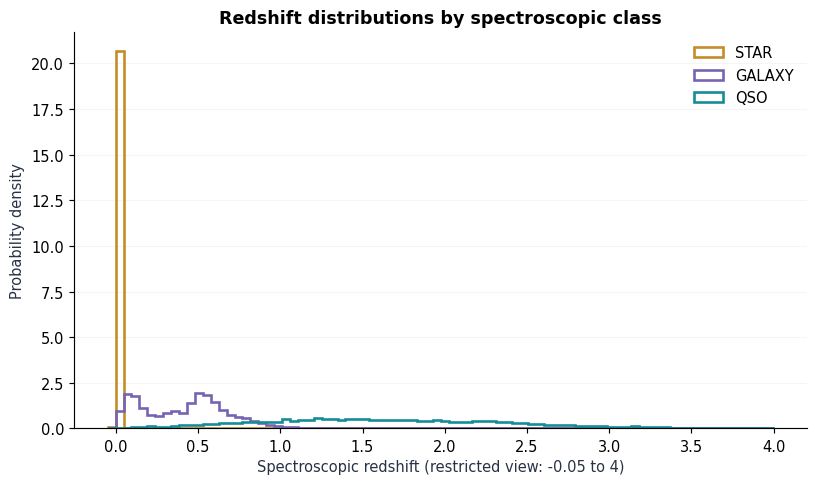

Redshift is descriptive here; it will be excluded from the baseline ML input matrix.


In [10]:
redshift_stats = df.groupby("class")["redshift"].agg(["count","mean","median","std","min","max"]).reindex(CLASSES)
redshift_stats.to_csv(REPORT_DIR / "phase2_redshift_descriptive_statistics.csv")
display(redshift_stats.round(4))

fig, ax = plt.subplots(figsize=(9, 4.9))
bins = np.linspace(-.05, 4.0, 85)
for cls in CLASSES:
    values = df.loc[df["class"]==cls,"redshift"]
    ax.hist(values, bins=bins, density=True, histtype="step", linewidth=1.8,
            label=cls, color=CLASS_COLOR[cls])
ax.set(xlabel="Spectroscopic redshift (restricted view: -0.05 to 4)",
       ylabel="Probability density", title="Redshift distributions by spectroscopic class")
ax.legend(frameon=False)
ax.grid(axis="y",alpha=.12)
save_plot("08_redshift_by_class_exploratory_only.png")
print("Redshift is descriptive here; it will be excluded from the baseline ML input matrix.")

## 8. Outliers and normality diagnostics

**Tukey's IQR rule** marks values outside $[Q_1-1.5\,IQR,\;Q_3+1.5\,IQR]$. A flagged value is **not necessarily erroneous**, especially with astronomical data, class mixtures and skewed measurements.

We count potential outliers (without deleting them), and inspect Q–Q plots to see how distributions differ from an ideal Gaussian. Because a very large sample can make a formal normality test sensitive to tiny departures, visual diagnostics and effect sizes are more useful than a single p-value.

,lower_fence,upper_fence,flagged_count,flagged_percent
feature,,,,
u,15.350,28.690,55,0.055
g,14.227,26.862,98,0.098
r,13.772,25.408,132,0.132
i,13.736,24.393,198,0.198
z,13.770,23.612,319,0.319


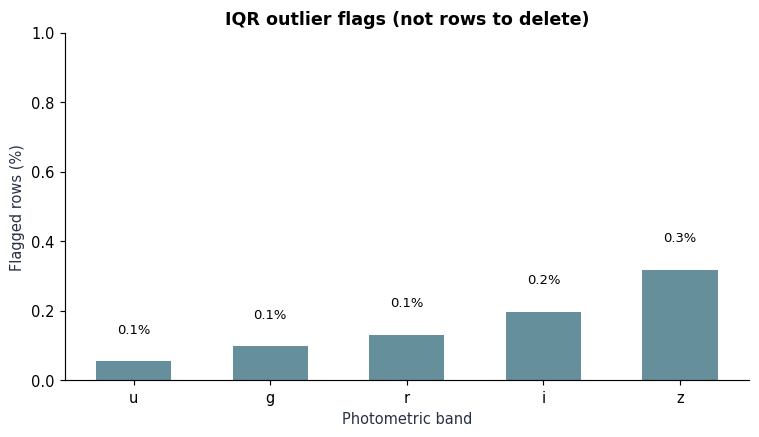

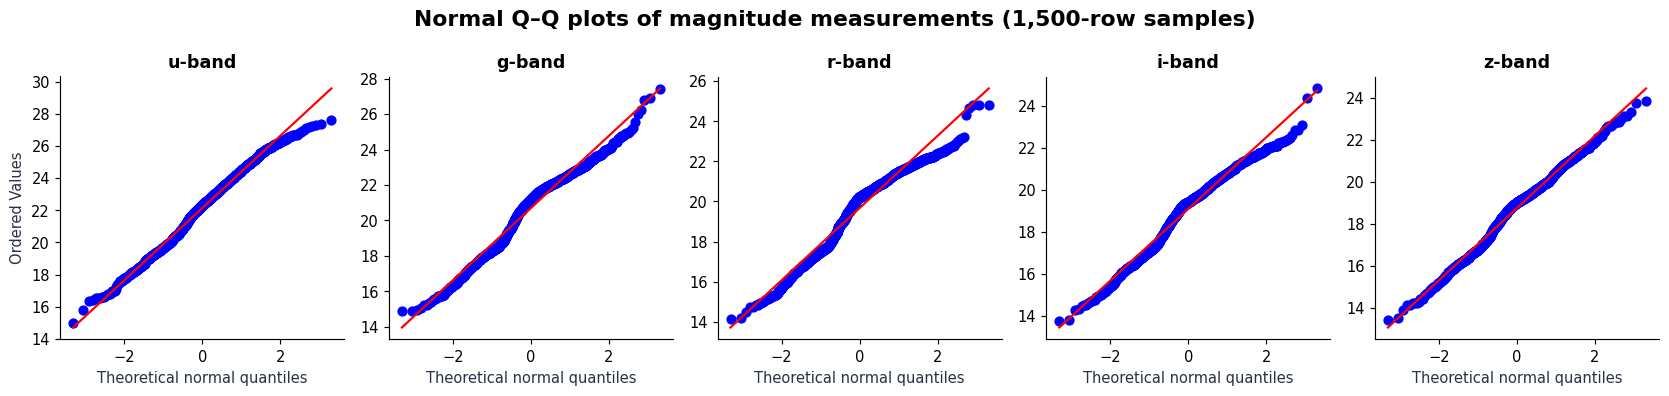

In [11]:
outlier_rows = []
for band in BANDS:
    q1,q3 = df[band].quantile([.25,.75])
    iqr = q3-q1
    low, high = q1-1.5*iqr,q3+1.5*iqr
    count = int(((df[band]<low)|(df[band]>high)).sum())
    outlier_rows.append({"feature":band,"lower_fence":low,"upper_fence":high,
                         "flagged_count":count,"flagged_percent":count/len(df)*100})
outliers = pd.DataFrame(outlier_rows).set_index("feature")
outliers.to_csv(REPORT_DIR / "phase2_iqr_outlier_flags.csv")
display(outliers.round(3))

fig, ax = plt.subplots(figsize=(8.4,4.3))
ax.bar(outliers.index, outliers["flagged_percent"],color="#648f9b",width=.55)
for idx, val in enumerate(outliers["flagged_percent"]):
    ax.text(idx, val + .08, f"{val:.1f}%", ha="center", fontsize=9)
ax.set(xlabel="Photometric band",ylabel="Flagged rows (%)",title="IQR outlier flags (not rows to delete)")
ax.set_ylim(0,max(1,outliers["flagged_percent"].max()*1.19))
save_plot("09_iqr_outlier_flags.png")

fig,axes=plt.subplots(1,5,figsize=(16,3.8))
for i,(ax,band) in enumerate(zip(axes,BANDS)):
    sample = df[band].sample(n=1500,random_state=SEED).to_numpy()
    stats.probplot(sample,dist="norm",plot=ax)
    ax.set_title(f"{band}-band")
    ax.set_xlabel("Theoretical normal quantiles")
    if i: ax.set_ylabel("")
fig.suptitle("Normal Q–Q plots of magnitude measurements (1,500-row samples)",fontsize=15,fontweight="bold")
fig.tight_layout()
save_plot("10_normal_qq_plots.png")

## 9. Statistical class comparison: Kruskal–Wallis and $\eta^2$

**Question:** Are the three spectroscopic groups measurably different on each photometric feature?

- **Kruskal–Wallis** is a nonparametric test that compares group rank distributions. For computational balance, we sample **2,500 observations per class** for this exploratory test; the same sampling rule is applied to every class.
- **$\eta^2$** is the one-way ANOVA *descriptive effect size*, calculated from the full dataset:

$$\eta^2=\frac{\sum_c n_c(\bar{x}_c-\bar{x})^2}{\sum_i(x_i-\bar{x})^2}.$$

It estimates the share of total sample variance attributable to between-class mean differences for one feature. **It does not prove causal importance, nor does it measure a trained model's predictive accuracy.** The tests are exploratory and multiple testing should be acknowledged.

,feature,kruskal_H,raw_p,bonferroni_p,eta_squared
6,g_r,3355.09668,0.0,0.0,0.32602
7,r_i,2606.45576,0.0,0.0,0.19552
4,z,2074.75867,0.0,0.0,0.16897
3,i,1747.23336,0.0,0.0,0.14211
5,u_g,2064.46778,0.0,0.0,0.11763
2,r,1008.83828,0.0,0.0,0.08399
0,u,535.42512,0.0,0.0,0.07736
1,g,688.42450,0.0,0.0,0.06829
8,i_z,1357.61792,0.0,0.0,0.06387


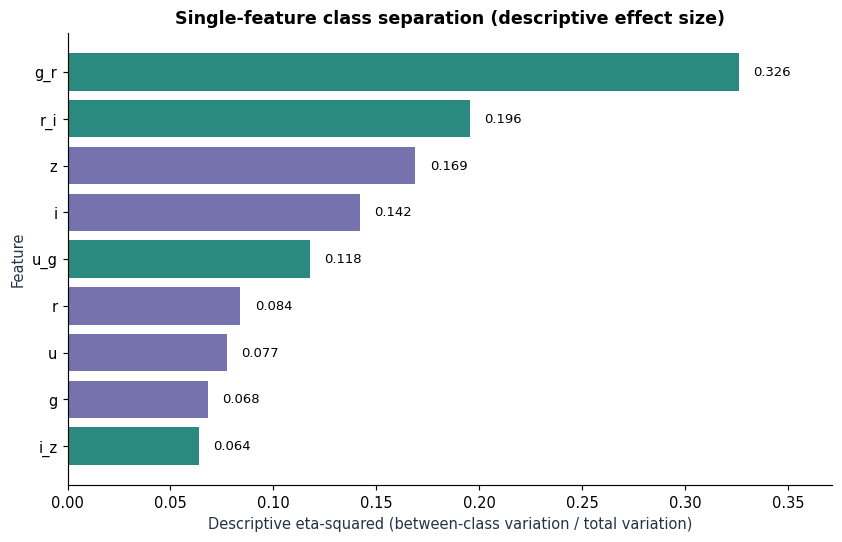

In [12]:
all_features=BANDS+COLORS
per_group_sample = {
    cls: eda[eda["class"]==cls].sample(n=2500,random_state=SEED)
    for cls in CLASSES
}
test_rows=[]
for f in all_features:
    groups=[per_group_sample[cls][f].to_numpy() for cls in CLASSES]
    h,p=stats.kruskal(*groups)
    mu=eda[f].mean()
    between=sum(len(group)*(group.mean()-mu)**2 for group in
                [eda.loc[eda["class"]==cls, f] for cls in CLASSES])
    total=((eda[f]-mu)**2).sum()
    eta2=float(between/total) if total else 0.0
    test_rows.append({"feature":f,"kruskal_H":float(h),"raw_p":float(p),
                      "bonferroni_p":float(min(1,p*len(all_features))),"eta_squared":eta2})
test_results=pd.DataFrame(test_rows).sort_values("eta_squared",ascending=False)
test_results.to_csv(REPORT_DIR / "phase2_class_comparison_tests.csv",index=False)
display(test_results.round(5))

fig,ax=plt.subplots(figsize=(9.4,5.6))
ordered=test_results.sort_values("eta_squared")
barcolors=["#2b8a80" if f in COLORS else "#7572ad" for f in ordered.feature]
ax.barh(ordered.feature,ordered.eta_squared,color=barcolors)
ax.set(xlabel="Descriptive eta-squared (between-class variation / total variation)",
       ylabel="Feature",title="Single-feature class separation (descriptive effect size)")
ax.set_xlim(0,max(.05,test_results.eta_squared.max()*1.14))
for idx,value in enumerate(ordered.eta_squared):
    ax.text(value+ .007,idx,f"{value:.3f}",va="center",fontsize=9)
save_plot("11_class_difference_effect_sizes.png")

## 10. Optional: sky-position plot (survey selection effects)

Right ascension (`alpha`) and declination (`delta`) determine where an observation lies on the celestial sphere. The survey footprint is *not* random sky coverage. We plot a small balanced sample to illustrate potential spatial selection effects.

This figure should **not** be used as evidence that sky position causes an object to belong to a particular class.

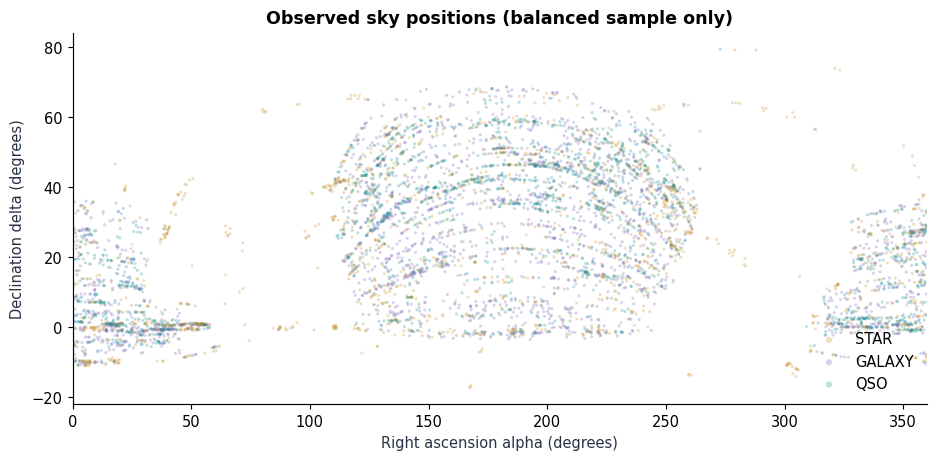

In [13]:
fig,ax=plt.subplots(figsize=(10.5,4.6))
for cls in CLASSES:
    subs = eda[eda["class"]==cls].sample(n=2000,random_state=SEED)
    ax.scatter(subs["alpha"],subs["delta"],s=4.5,alpha=.28,
               color=CLASS_COLOR[cls],label=cls,rasterized=True,edgecolors="none")
ax.set(xlabel="Right ascension alpha (degrees)",ylabel="Declination delta (degrees)",
       title="Observed sky positions (balanced sample only)")
ax.set_xlim(0,360)
ax.legend(frameon=False,loc="lower right",markerscale=2)
save_plot("12_sky_coverage_sample.png")

## 11. Export dashboard-ready data and machine-readable summaries

These files let your team build a Looker Studio dashboard without reopening the notebook. The `dashboard_photometry_sample.csv` contains a **balanced visualization sample** (up to 3,000 rows per class), not a random proportional sample. It includes `redshift` only for a **separately labeled exploratory chart**.

**Do not use this sample for training or final evaluation**; it is for dashboard rendering only.

In [14]:
dashboard_cols=["class"]+BANDS+COLORS+["redshift","alpha","delta"]
dashboard_data=plot_samples[dashboard_cols].copy()
dashboard_data.to_csv(DASH_DIR/"dashboard_photometry_sample.csv",index=False)

class_by_band=eda.groupby("class")[BANDS].agg(["mean","median","std"])
class_by_band.columns=["{}_{}".format(a,b) for a,b in class_by_band.columns]
class_by_band.to_csv(REPORT_DIR/"phase2_class_band_statistics.csv")

checks={
  "rows":int(len(df)), "columns_original":int(df.shape[1]),
  "classes":{k:int(v) for k,v in counts.items()},
  "null_cells":int(df.isna().sum().sum()),
  "invalid_photometric_sentinels":int(df[BANDS].eq(-9999).sum().sum()),
  "pearson_i_z":float(pearson.loc["i","z"]),
  "top_eta_squared_feature":str(test_results.iloc[0]["feature"]),
  "top_eta_squared_value":float(test_results.iloc[0]["eta_squared"]),
  "dashboard_sample_size":int(len(dashboard_data)),
  "plotting_seed":SEED,
  "redshift_used_for_primary_ml":False,
}
with (REPORT_DIR/"phase2_validation_summary.json").open("w",encoding="utf-8") as f:
    json.dump(checks,f,indent=2)

print("Exported",len(list(FIG_DIR.glob("*.png"))),"EDA figures to",FIG_DIR)
print("Exported",len(list(REPORT_DIR.glob("*.csv"))),"CSV summary tables to",REPORT_DIR)
print("Exported dashboard sample:",len(dashboard_data),"records")

Exported 12 EDA figures to C:\Users\daksh\OneDrive\Desktop\ML Project\Astronomical-Object-Classification\figures\eda
Exported 10 CSV summary tables to C:\Users\daksh\OneDrive\Desktop\ML Project\Astronomical-Object-Classification\reports
Exported dashboard sample: 9000 records


## 12. Automatic written report and EDA takeaways

The following code writes a concise Markdown report using **actual computed values**, so the statements remain in sync with the notebook if the input dataset changes. It can be adapted for the university project report. No model accuracy is claimed at this stage.

In [15]:
report = f"""# Phase 2 — SDSS Exploratory Data Analysis Report

**Project:** Astronomical Object Classification Using Machine Learning  
**Data:** `{DATA_FILE.name}` | **Observations:** {len(df):,} | **Columns:** {len(df.columns)}

## Dataset and target distribution

- GALAXY: {int(counts['GALAXY']):,} ({counts['GALAXY']/len(df):.2%})
- STAR: {int(counts['STAR']):,} ({counts['STAR']/len(df):.2%})
- QSO: {int(counts['QSO']):,} ({counts['QSO']/len(df):.2%})
- Majority-class baseline accuracy: {counts.max()/len(df):.2%}; future evaluations require class-wise recall and macro F1.
- Quality check: {df.isna().sum().sum()} null cells, {int(df[BANDS].eq(-9999).sum().sum())} invalid photometric sentinels after Phase 1.

## Key quantitative findings

1. Five-band photometry is associated with the spectroscopic class labels, but class distributions overlap.
2. Adjacent `i` and `z` bands are strongly correlated: Pearson r = {pearson.loc['i','z']:.4f}. Correlation does not justify automatic feature deletion.
3. Median `u-g`: STAR = {color_medians.loc['STAR','u_g']:.3f}, GALAXY = {color_medians.loc['GALAXY','u_g']:.3f}, QSO = {color_medians.loc['QSO','u_g']:.3f}.
4. Median `g-r`: STAR = {color_medians.loc['STAR','g_r']:.3f}, GALAXY = {color_medians.loc['GALAXY','g_r']:.3f}, QSO = {color_medians.loc['QSO','g_r']:.3f}.
5. Highest single-feature eta-squared: `{test_results.iloc[0]['feature']}` ({test_results.iloc[0]['eta_squared']:.3f}). This is descriptive class separation, **not** predictive accuracy.
6. Median redshifts STAR = {redshift_stats.loc['STAR','median']:.3f}, GALAXY = {redshift_stats.loc['GALAXY','median']:.3f}, QSO = {redshift_stats.loc['QSO','median']:.3f}. **Redshift is excluded from the primary photometry-only model.**

## Interpretation

Magnitudes are measurements on an inverse brightness scale: smaller magnitude generally means brighter observed flux. Colour indices are the difference between two magnitudes and summarize their relative spectral profile. The observed group differences suggest that both raw magnitudes and engineered colour features deserve evaluation in Phase 4/5.

The IQR rule is a diagnostic, not a deletion policy. The distributions and survey footprint reflect the observed sample, not a population-universal property of all celestial objects. Tiny statistical p-values in a very large dataset are not automatically evidence of practical predictive value.

## Next research questions

1. Do the four colour indices improve cross-validated macro F1 relative to the five-band baseline?
2. Which spectroscopic classes are confused in a purely photometric classifier?
3. How much performance changes if additional *spectroscopic* redshift is supplied, clearly labeled as a separate task?
4. Are results stable across stratified validation folds?

## Deliverables

- `notebooks/02_exploratory_data_analysis.ipynb`
- `figures/eda/*.png` (12 figures)
- `reports/phase2_*.csv`, `reports/phase2_validation_summary.json`
- `dashboard/dashboard_photometry_sample.csv` (balanced visualization sample)

## Sources and caveats

- https://www.sdss4.org/dr12/imaging/understanding-the-imaging-data/
- https://www.sdss4.org/dr17/algorithms/magnitudes/
- https://www.kaggle.com/datasets/fedesoriano/stellar-classification-dataset-sdss17

SDSS magnitudes may be expressed as asinh magnitudes. The CSV alone does not specify a unique photometric measurement estimator or provide per-band measurement errors. Avoid claiming universal astrophysical rules from this selected catalog sample.
"""
(REPORT_DIR/"Phase2_EDA_Report.md").write_text(report,encoding="utf-8")
print(report[:2600])

# Phase 2 — SDSS Exploratory Data Analysis Report

**Project:** Astronomical Object Classification Using Machine Learning  
**Data:** `sdss_cleaned.csv` | **Observations:** 99,999 | **Columns:** 18

## Dataset and target distribution

- GALAXY: 59,445 (59.45%)
- STAR: 21,593 (21.59%)
- QSO: 18,961 (18.96%)
- Majority-class baseline accuracy: 59.45%; future evaluations require class-wise recall and macro F1.
- Quality check: 0 null cells, 0 invalid photometric sentinels after Phase 1.

## Key quantitative findings

1. Five-band photometry is associated with the spectroscopic class labels, but class distributions overlap.
2. Adjacent `i` and `z` bands are strongly correlated: Pearson r = 0.9715. Correlation does not justify automatic feature deletion.
3. Median `u-g`: STAR = 1.319, GALAXY = 1.640, QSO = 0.393.
4. Median `g-r`: STAR = 0.527, GALAXY = 1.404, QSO = 0.214.
5. Highest single-feature eta-squared: `g_r` (0.326). This is descriptive class separation, **not** predictive accuracy.

## 13. Chalk-talk preparation: questions and explanations

**Q1. Why are magnitudes inverse?**  
In the magnitude system, a lower magnitude generally means greater observed flux. An ordinary 1-mag difference corresponds to a flux ratio about 2.512; SDSS asinh magnitudes need some care at low signal to noise.

**Q2. Why compare median and mean?**  
The mean is affected by extreme observations; the median is resistant to a small number of extreme values.

**Q3. Why compute skewness and kurtosis?**  
They provide summaries of asymmetry and tail weight; they are descriptive, and should be checked together with plots.

**Q4. What does a colour index like $g-r$ measure?**  
A difference between apparent magnitudes in two filters, indicating the relative spectral profile across those bands.

**Q5. Why compare Pearson and Spearman?**  
Pearson detects linear association; Spearman describes rank-based monotonic association and is less driven by extreme magnitudes.

**Q6. Does correlation imply redundancy?**  
No. Features can be correlated and still provide complementary information useful to a classifier.

**Q7. What is an IQR outlier?**  
A value outside the Tukey fences. It is a statistical flag, **not proof of bad data**.

**Q8. Why not use redshift for the primary classifier?**  
It is spectroscopic information; our primary research question is what can be classified using **photometry alone**.

**Q9. Why not train on the balanced dashboard sample?**  
It is a plotting convenience and changes the class proportions. Model training and evaluation will use the full cleaned dataset and correctly designed splits.

**Q10. How does this prepare Phase 4?**  
It identifies meaningful colour indices and potential correlations while avoiding premature feature selection based on test results.

---

### Phase 2 completion checklist

- [x] Loaded and validated the cleaned Phase 1 CSV
- [x] Target class balance chart
- [x] Full five-band descriptive statistics
- [x] Class-wise histograms and boxplots
- [x] Pearson and Spearman correlation heatmaps
- [x] Derived and visualized four colour indices
- [x] Separate redshift visualization
- [x] IQR / Q-Q analysis
- [x] Exploratory Kruskal–Wallis and $\eta^2$ comparison
- [x] Exported 12 figures, summary CSVs and a written report

**Next:** Phase 3 dashboard (optional) and Phase 4 feature engineering / leakage prevention.